In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df_pr = pd.read_csv('products_clean.csv')
df_o = pd.read_csv('orders_clean.csv')
df_rw = pd.read_csv('reviews_clean.csv')

In [12]:
df_pr.info()

<class 'pandas.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   product_id     600 non-null    str    
 1   product_name   600 non-null    str    
 2   category       600 non-null    str    
 3   sub_category   600 non-null    str    
 4   list_price     600 non-null    float64
 5   unit_cost      600 non-null    float64
 6   seller_id      600 non-null    str    
 7   quality_score  600 non-null    float64
dtypes: float64(3), str(5)
memory usage: 68.0 KB


In [11]:
df_pr['category'].unique()

<ArrowStringArray>
[         'Books',    'Electronics',         'Sports', 'Home & Kitchen',
        'Fashion',        'Grocery',         'Beauty',           'Toys']
Length: 8, dtype: str

In [10]:
df_pr['category'] = df_pr['category'].replace({'Electronic':'Electronics'})

In [17]:
df_o.info()

<class 'pandas.DataFrame'>
RangeIndex: 29951 entries, 0 to 29950
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   order_id       29951 non-null  str           
 1   customer_id    29065 non-null  str           
 2   order_date     29951 non-null  datetime64[us]
 3   product_id     29951 non-null  str           
 4   seller_id      29951 non-null  str           
 5   quantity       29951 non-null  int64         
 6   list_price     29951 non-null  float64       
 7   discount_pct   29951 non-null  int64         
 8   sales_amount   29951 non-null  float64       
 9   cost_amount    29951 non-null  float64       
 10  profit         29951 non-null  float64       
 11  order_status   29951 non-null  str           
 12  shipping_days  29951 non-null  int64         
dtypes: datetime64[us](1), float64(4), int64(3), str(5)
memory usage: 3.9 MB


In [13]:
df_o['order_date'] = pd.to_datetime(df_o['order_date'])

In [16]:
df_o['shipping_days'] = df_o['shipping_days'].astype(int)

In [20]:
df_rw.info()

<class 'pandas.DataFrame'>
RangeIndex: 18854 entries, 0 to 18853
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   review_id    18854 non-null  str           
 1   order_id     18854 non-null  str           
 2   product_id   18854 non-null  str           
 3   customer_id  18854 non-null  str           
 4   rating       18854 non-null  int64         
 5   review_date  18854 non-null  datetime64[us]
 6   review_text  18854 non-null  str           
dtypes: datetime64[us](1), int64(1), str(5)
memory usage: 1.6 MB


In [19]:
df_rw['review_date'] = pd.to_datetime(df_rw['review_date'])

ok now all tables are good

### 1. Sales per product (how much each product sold)

In [25]:
po = df_o[df_o['order_status'] != 'Cancelled']
sales = po.groupby('product_id').agg(orders = ('order_id', 'count'), revenue = ('sales_amount', 'sum')).reset_index()

In [27]:
sales.head()

,product_id,orders,revenue
0,P0001,21,24259.30
1,P0002,9,19678.16
2,P0003,28,20616.00
3,P0004,13,9186.54
4,P0005,28,21242.02


### 2 . Rating per product

In [29]:
rate = df_rw.groupby('product_id').agg(avg_rating = ('rating', 'mean'), n_reviews = ('rating', 'count')).reset_index()

In [30]:
rate.head()

,product_id,avg_rating,n_reviews
0,P0001,3.500000,16
1,P0002,3.500000,4
2,P0003,4.608696,23
3,P0004,4.571429,7
4,P0005,4.842105,19


In [31]:
sales_rate = sales.merge(rate, on = 'product_id')
df = sales_rate.merge(df_pr[['product_name','product_id', 'category']], on = 'product_id')

In [32]:
df.head()

,product_id,orders,revenue,avg_rating,n_reviews,product_name,category
0,P0001,21,24259.30,3.500000,16,Grocery Item 1,Grocery
1,P0002,9,19678.16,3.500000,4,Toys Item 2,Toys
2,P0003,28,20616.00,4.608696,23,Beauty Item 3,Beauty
3,P0004,13,9186.54,4.571429,7,Fashion Item 4,Fashion
4,P0005,28,21242.02,4.842105,19,Toys Item 5,Toys


In [34]:
df = df[df['n_reviews']>=15]

A product with 2 reviews and a 5-star average isn’t reliable, so 15 is the minimum I used.

In [35]:
df.head()

,product_id,orders,revenue,avg_rating,n_reviews,product_name,category
0,P0001,21,24259.30,3.500000,16,Grocery Item 1,Grocery
2,P0003,28,20616.00,4.608696,23,Beauty Item 3,Beauty
4,P0005,28,21242.02,4.842105,19,Toys Item 5,Toys
5,P0006,32,2259876.00,2.478261,23,Electronics Item 6,Electronics
6,P0007,24,61074.73,4.117647,17,Electronics Item 7,Electronics


In [36]:
df.shape

(234, 7)

### 3. High Sales & Poor Rating Products

In [40]:
high_sales = df['orders'].quantile(0.75)  # top 25% by number of orders
df['risk'] = (df['orders'] >= high_sales) & (df['avg_rating'] < 3.5)
risky = df[df['risk']].sort_values('orders', ascending=False)

In [41]:
print(len(risky), 'risky products')

29 risky products


In [45]:
print(risky[['product_name', 'category', 'orders', 'revenue', 'avg_rating']].head(10).round(2))

                product_name        category  orders     revenue  avg_rating
418            Toys Item 419            Toys    3625  8533561.61        3.34
87           Fashion Item 88         Fashion    1300   711440.08        3.46
171          Sports Item 172          Sports     973  3787502.62        2.70
123           Books Item 124           Books     320    91088.86        3.25
538           Books Item 539           Books     314   255884.50        3.34
577  Home & Kitchen Item 578  Home & Kitchen     296   212936.54        3.16
325         Fashion Item 326         Fashion     270   253338.48        2.75
510     Electronics Item 511     Electronics     251   730290.61        3.44
187           Books Item 188           Books     172    82397.06        2.78
405         Fashion Item 406         Fashion     157   377686.85        3.10


In [46]:
print(risky['category'].value_counts())

category
Fashion           7
Books             7
Electronics       5
Sports            4
Toys              3
Home & Kitchen    2
Grocery           1
Name: count, dtype: int64


In [48]:
print('Revenue share of risky products %:', round(risky['revenue'].sum() / po['sales_amount'].sum() * 100, 1))

Revenue share of risky products %: 17.2


## VISUALIZATION

### 1. Sales vs rating for every product

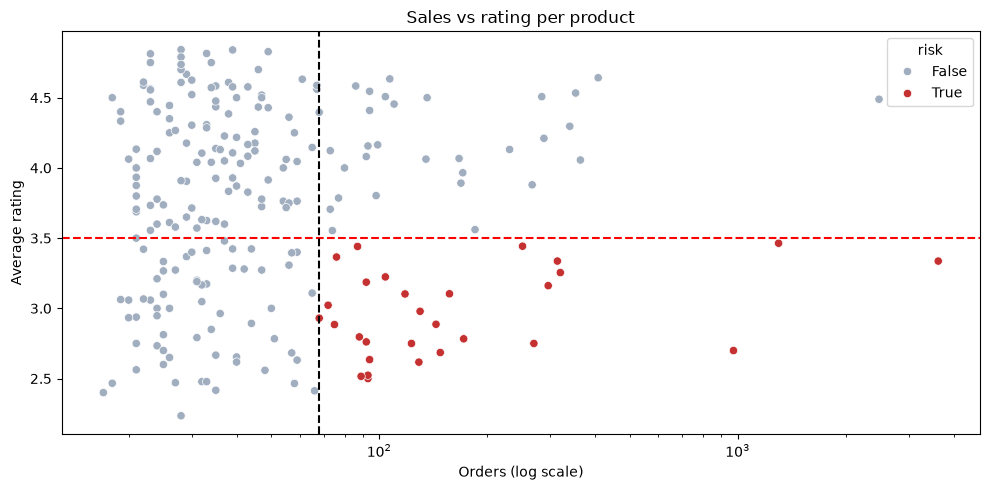

In [66]:
plt.figure(figsize=(10,5))
sns.scatterplot(data =df, x = 'orders', y ='avg_rating', hue='risk', palette={False: '#a0aec0', True: '#c53030'})
plt.xscale('log')
plt.axhline(3.5, color = 'red', linestyle = '--') # poor rating line
plt.axvline(high_sales, color = 'black', linestyle = '--') # high sales line
plt.xlabel('Orders (log scale)'); plt.ylabel('Average rating')
plt.title('Sales vs rating per product')
plt.tight_layout();
plt.show()

Most products are safe. 
The red dots in the bottom-right corner are the problem: many people buy them, but many people rate them badly. 
There are 29 of them.

### 2. Top 10 risky products by orders

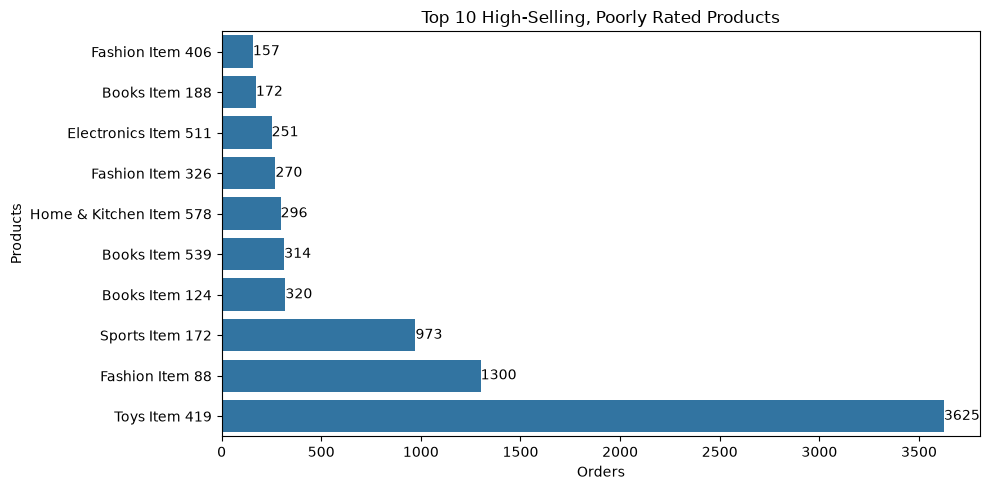

In [62]:
top = risky.head(10).sort_values('orders')

plt.figure(figsize=(10,5))
ax = sns.barplot(data=top, x='orders', y='product_name')
ax.bar_label(ax.containers[0])
plt.xlabel('Orders')
plt.ylabel('Products')
plt.title('Top 10 High-Selling, Poorly Rated Products')
plt.tight_layout();
plt.show()

Toys Item 419 is the biggest worry. 
It has by far the most orders and a rating of only 3.33. 
Sports Item 172 is the worst rated (2.67) and still sells 973 times.

### 3. Categories having the risky products

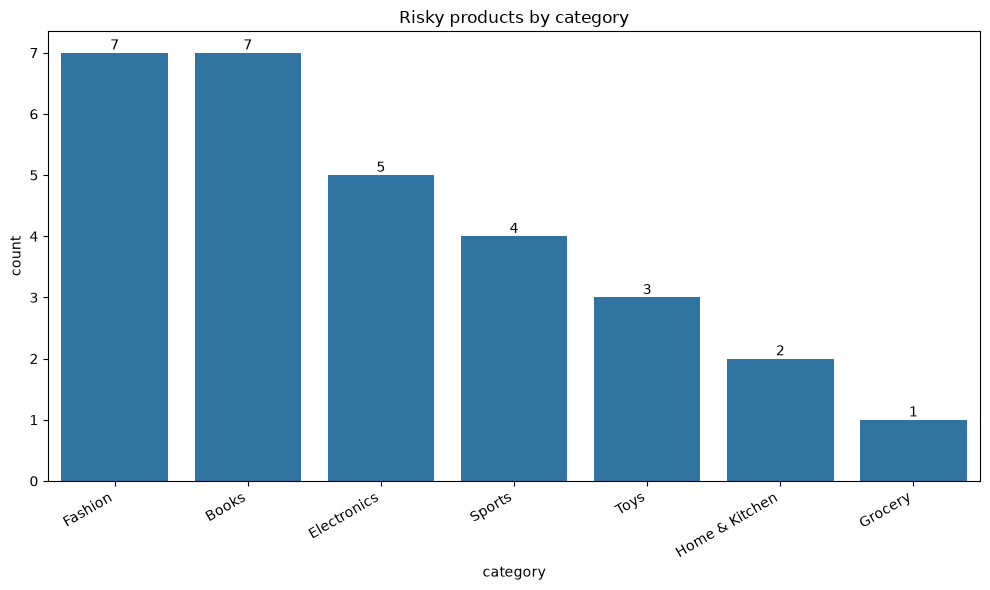

In [65]:
cr = risky['category'].value_counts().reset_index()

plt.figure(figsize=(10,6))
bar = sns.barplot(data=cr, x='category', y='count')
bar.bar_label(bar.containers[0])
plt.xticks(rotation=30, ha='right')
plt.title('Risky products by category')
plt.tight_layout(); 
plt.show()

The risky products are spread across categories. 
Fashion and Books have 7 each, then Electronics with 5.

These 29 products bring about 17.2% of all revenue, so fixing them matters.

### What the company should do: